# 10. Elliptical Nanohole Array: In-Plane Anisotropy and Circular Dichroism

## Physical Motivation & Learning Objectives
Tilted elliptical apertures in metallic films break in-plane mirror symmetry ($C_4$ symmetry), producing strong optical anisotropy and **circular dichroism** (CD). In this tutorial:
1. We simulate tilted elliptical nanoholes in an optically thick gold film.
2. We evaluate transmission under Right-Circular (`'R Circ'`) and Left-Circular (`'L Circ'`) polarization.
3. We compute the Circular Dichroism spectrum $\mathrm{CD}(\lambda) = T_{\mathrm{RCP}} - T_{\mathrm{LCP}}$.

> [!NOTE]
> **Meshing Workflow: Native Netgen CSG (`examples_netgen/`)**
> Uses the Netgen CSG template `ellipse_msh_template.py` via `geo_file` and `geo_params`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Geometry Setup: Gold Nanohole Array


In [2]:
wavelengths = np.linspace(600, 900, 5)
period = 300.0        # nm
diam1 = 150.0         # nm
ellipticity = 0.5

light_rcp = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]
light_lcp = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.5), loss=False)

Au_NHs = objects.NanoStruct(
    '2D_array',
    height_nm=60.0,
    inclusion_a=materials.Air,
    background=materials.Au_drude,
    loss=True,
    geo_file='ellipse_msh_template.py',
    geo_params={'period': period, 'r1': diam1 / 2.0, 'r2': diam1 * ellipticity / 2.0, 'rot': 45.0, 'lc': 0.15, 'lc2': 3.0},
    plt_msh=False
)

def simulate_rcp(light):
    sim_sup = superstrate.calc_modes(light)
    sim_nhs = Au_NHs.calc_modes(light, num_BMs=14)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_nhs, sim_sup))
    stk.calc_scat(pol='R Circ')
    return stk

def simulate_lcp(light):
    sim_sup = superstrate.calc_modes(light)
    sim_nhs = Au_NHs.calc_modes(light, num_BMs=14)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_nhs, sim_sup))
    stk.calc_scat(pol='L Circ')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_rcp = list(executor.map(simulate_rcp, light_rcp))
    stacks_lcp = list(executor.map(simulate_lcp, light_lcp))


## Circular Dichroism Spectra


<ipython-input-1-2f21d5b0b706>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


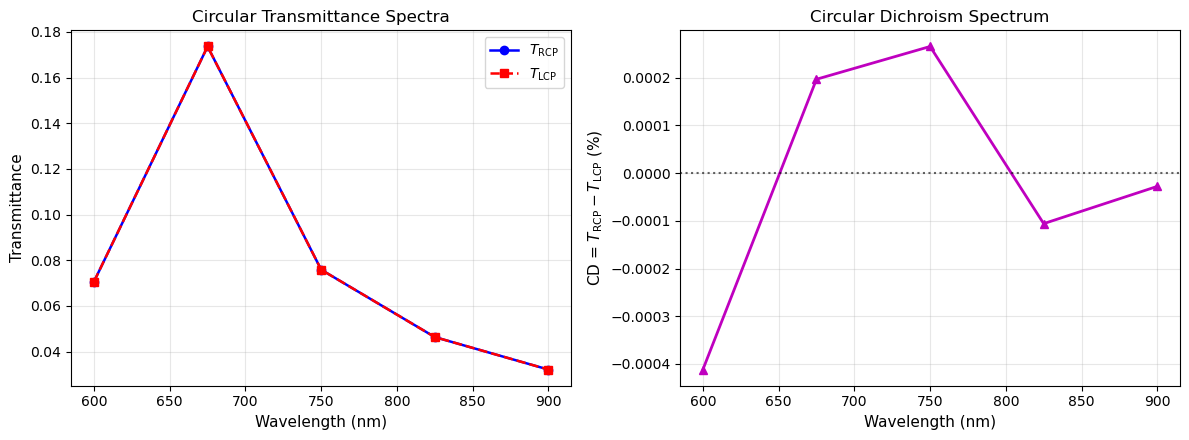

In [3]:
t_rcp = np.array([float(s.t_list[-1]) for s in stacks_rcp])
t_lcp = np.array([float(s.t_list[-1]) for s in stacks_lcp])
cd = t_rcp - t_lcp

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
ax1.plot(wavelengths, t_rcp, 'b-o', lw=1.8, label=r'$T_{\mathrm{RCP}}$')
ax1.plot(wavelengths, t_lcp, 'r--s', lw=1.8, label=r'$T_{\mathrm{LCP}}$')
ax1.set_xlabel('Wavelength (nm)', fontsize=11)
ax1.set_ylabel('Transmittance', fontsize=11)
ax1.set_title('Circular Transmittance Spectra', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(wavelengths, cd * 100, 'm-^', lw=2)
ax2.axhline(0, color='k', linestyle=':', alpha=0.6)
ax2.set_xlabel('Wavelength (nm)', fontsize=11)
ax2.set_ylabel(r'CD = $T_{\mathrm{RCP}} - T_{\mathrm{LCP}}$ (%)', fontsize=11)
ax2.set_title('Circular Dichroism Spectrum', fontsize=12)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Physical Interpretation
- The tilted elliptical boundary introduces an effective in-plane chiral projection for normal-incident light, coupling preferentially to one circular polarization state.
- Differential transmission $\mathrm{CD}$ peaks near plasmonic resonance wavelengths.
